# 1. Podaci: preuzimanje, analiza i priprema

In [2]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from data import download, clean, split
from textprep import normalize

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

## 1.1 Preuzimanje iz baze

Iz baze mi treba samo tabela `ml_dataset`. Povlačim je jednim `SELECT *` upitom.

In [3]:
raw = download("../data/ml_dataset.csv")
print(raw.shape)
raw.head()

(50000, 5)


,category_id,group_id,category_name,group_name,name
0,23,489,Mobilni telefoni,Apple iPhone,iPhone 8 64gb BH 85% DOBAR
1,23,489,Mobilni telefoni,Apple iPhone,iphone 14 yellow 128gb
2,23,489,Mobilni telefoni,Apple iPhone,OTKUP iPhone 11 Pro / Pro Max
3,23,489,Mobilni telefoni,Apple iPhone,Apple iPhone 15 128GB Black
4,23,489,Mobilni telefoni,Apple iPhone,iPhone 11 Pro 64gb otvoren na sve mreze (sim-free)


## 1.2 Osnovna analiza

Tabela ima 5 kolona, ali kao ulaz modela koristim samo `name` (naslov oglasa). `group_id` je labela koju predviđam, a `group_name`, `category_id` i `category_name` su samo druga imena iste informacije.



In [4]:
print(raw.isna().sum())
groups = (raw.groupby(["group_id", "group_name", "category_name"]).size()
             .rename("broj_oglasa").reset_index())
groups

category_id      0
group_id         0
category_name    0
group_name       0
name             0
dtype: int64


,group_id,group_name,category_name,broj_oglasa
0,232,Placevi i zemljište,Nekretnine | Kupoprodaja,5000
1,405,Kreveti i dušeci,Nameštaj,5000
2,489,Apple iPhone,Mobilni telefoni,5000
3,589,Sličice i albumi,Kolekcionarstvo,5000
4,769,"Upaljači, tabakere i pljoske","Nakit, satovi i dragocenosti",5000
5,973,Električne brusilice,Alati i oruđa,5000
6,1142,Plišane igračke,Igračke i igre,5000
7,1277,Motokultivatori | Delovi i oprema,Poljoprivreda,5000
8,2173,"Samsung | Futrole, maske i folije",Mobilni tel. | Oprema i delovi,5000
9,2663,"Roštilji, grilovi i friteze",Bela tehnika i kućni aparati,5000


Ima 10 grupa sa po 5000 naziva, bez praznih vrednosti. Klase su savršeno izbalansirane, pa za sada ne treba `over/under sampling`. Pošto je tako, `accuracy` je smislena metrika. Posle čišćenja duplikata balans će se promeniti, pa ću ga proveriti ponovo.

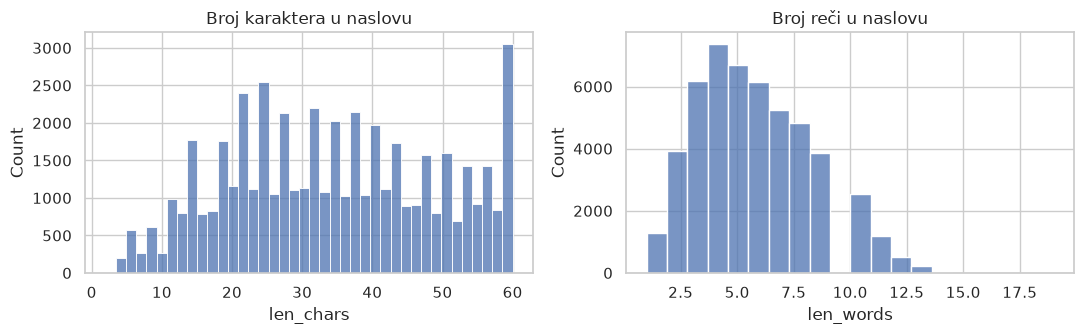

,count,mean,std,min,25%,50%,75%,max
len_chars,50000.0,34.44134,14.765262,2.0,23.0,34.0,46.0,60.0
len_words,50000.0,5.70240,2.621078,1.0,4.0,5.0,8.0,19.0


In [5]:
raw["len_chars"] = raw["name"].str.len()
raw["len_words"] = raw["name"].str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(raw["len_chars"], bins=40, ax=ax[0]); ax[0].set_title("Broj karaktera u naslovu")
sns.histplot(raw["len_words"], bins=20, ax=ax[1]); ax[1].set_title("Broj reči u naslovu")
plt.tight_layout(); plt.show()
raw[["len_chars", "len_words"]].describe().T

In [6]:
for g, s in raw.groupby("group_name"):
    print(f"--- {g}")
    for t in s["name"].sample(6, random_state=0):
        print("   ", t)

--- Apple iPhone
    NOVO iPhone 16 128Gb
    Otkup Telefona Iphone 12 Pro 512gb Pacific Blue
    Iphone 6-32gb Br.B6
    rezervisana iPhone 12 pro 256gb ploca otkljucana simfree
    iPhone 11 Pro Midnight Green 64GB /PERFEKTAN/
    iPhone 8 64 GB Refurbished GARANCIJA 12 MESECI A KLASA
--- Električne brusilice
    Čeona brusilica bijaks
    PROcut Mašinska čelična četka, kružna fi115mm
    Električna ugaona brusilica VLP 407
    Ugaona brusilica Total 2400w TG1252306
    Brusilica Odingoi 850 w Novo
    Brusilica velika Metabo WE 26-230 MVT Quick;2600W(606475000)
--- Kreveti i dušeci
    Krevet i ugaoni orman
    Nameštaj "MATA" Francuski ležaj "LUX"
    Krevet
    Bracni krevet sa dusekom Numanovic i dva nocnika
    Krevet CAPITONE
    Krevet
--- Motokultivatori | Delovi i oprema
    lamela muta goranje
    Ekscentar sajbna Kipor
    Rucica gumena - startera IMT 506
    Sajla Paljenja IMT 506 sajla starta
    bombina elektronskog paljenja colil imt 506
    IMT 507 Pogonska osovina 50

## 1.3 Duplikati

U slucaju da isti naslov završi i u trening i u test skupu, model ga samo "zapamti" i izmerena tačnost je preoptimistična. Zato brojim duplikate pre bilo kakve podele.

In [7]:
raw["text"] = raw["name"].map(normalize)
print("tacni duplikati naslova      :", raw.duplicated("name").sum())
print("duplikati posle normalizacije:", raw.duplicated("text").sum())
n_groups = raw.groupby("text")["group_id"].nunique()
conflict = n_groups[n_groups > 1]
print("naslova koji su u vise grupa :", len(conflict))
raw[raw["text"].isin(conflict.index)].sort_values("text")[["text", "group_name"]].head(12)

tacni duplikati naslova      : 7235
duplikati posle normalizacije: 8485
naslova koji su u vise grupa : 9


,text,group_name
24871,kuca,Placevi i zemljište
28993,kuca,Plišane igračke
28990,kuca,Plišane igračke
29517,kuca,Plišane igračke
25311,kuca,Plišane igračke
29004,kuca,Plišane igračke
29164,kuca,Plišane igračke
28601,leteca druzina,Plišane igračke
42471,leteca druzina,Sličice i albumi
12986,na prodaju,Kreveti i dušeci


Oko 17% redova su duplikati (8485 od 50000 posle normalizacije), a 9 naslova je istovremeno u različitim grupama (npr. `kuca` je i u plišanim igračkama i u placevima, `na prodaju` je u krevetima i u sličicama). Za takve naslove ne postoji tačan odgovor, pa ih izbacujem: učili bi model kontradiktornim primerima, a u testu bi bili nepravedno kažnjeni.



## 1.4 Normalizacija teksta

Namerno nisam radio stemming, jer nemam dobar stemmer za srpski koji ne bi pokvario brendove i oznake modela.

Ova normalizacija je pretpostavka, a ne dokazana odluka: njena korisnost za transformer se proverava u svesci 02, odeljak 2.4 (poređenje sa i bez normalizacije). Ovde se koristi i za otkrivanje duplikata, tako da se "Plišana igračka" i "plisana igracka" računaju kao isti naslov. Podela na trening/validaciju/test se pravi jednom i ista je za sve eksperimente.

In [7]:
for t in ["Plišane IGRAČKE!!", "ЦРНА Наруквица Apple Watch 2 | 38mm", "Električni roštilj Concept GE3500 DP", "ŠRAFCIGER Ćošak (Đurđevak) 100%"]:
    print(f"{t!r:55} -> {normalize(t)!r}")

'Plišane IGRAČKE!!'                                     -> 'plisane igracke'
'ЦРНА Наруквица Apple Watch 2 | 38mm'                   -> 'crna narukvica apple watch 2 38mm'
'Električni roštilj Concept GE3500 DP'                  -> 'elektricni rostilj concept ge3500 dp'
'ŠRAFCIGER Ćošak (Đurđevak) 100%'                       -> 'srafciger cosak djurdjevak 100'


## 1.5 Čišćenje i provera balansa

50000 -> 41506 oglasa


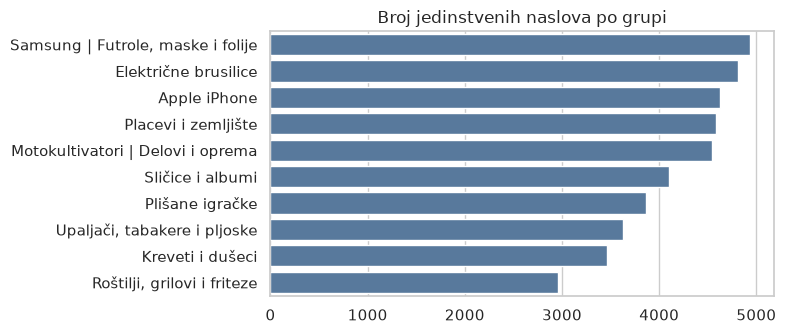

In [8]:
df = clean(raw[["category_id", "group_id", "category_name", "group_name", "name"]])
classes = (df[["group_id", "group_name"]].drop_duplicates().sort_values("group_id").reset_index(drop=True))
label_of = {g: i for i, g in enumerate(classes["group_id"])}
df["label"] = df["group_id"].map(label_of)
classes.to_csv("../data/classes.csv", index_label="label")
print(f"{len(raw)} -> {len(df)} oglasa")
counts = df["group_name"].value_counts()
plt.figure(figsize=(8, 3.5)); sns.barplot(x=counts.values, y=counts.index, color="#4c78a8")
plt.title("Broj jedinstvenih naslova po grupi"); plt.xlabel(""); plt.ylabel(""); plt.tight_layout(); plt.show()

Posle čišćenja klase više nisu savršeno izbalansirane (najviše duplikata imaju grupe sa generičkim naslovima, npr. roštilji i friteze, kreveti i dušeci). Razlika je umerena (najmanja klasa ima otprilike 60% najveće), pa je i dalje dovoljno da model izvuče pravilnosti iz svake klase. Zato ću u evaluaciji pratiti `macro F1`, koji svaku klasu računa podjednako, i pogledati rezultat po klasama.

## 1.6 Podela na trening / validaciju / test

Podela je 80% / 10% / 10%, stratifikovana (svaki skup ima isti odnos klasa).

* **trening** služi za učenje težina,
* **validacioni** služi za biranje arhitekture i hiperparametara (veličina mreže, regularizacija) i za rano zaustavljanje,
* **test** se ne dira dok se ne odabere konačan model i koristi se samo jednom, za završnu ocenu. Da sam birao model po test skupu, rezultat bi bio optimističan.

Podelu radim **pre** pravljenja rečnika i TF-IDF težina, jer bi se inače informacije iz validacije/testa "provukle" u trening (tzv. data leakage). Duplikati su već uklonjeni, tako da isti naslov ne može da bude u dva skupa.

In [9]:
train, val, test = split(df)
for name, d in [("train", train), ("val", val), ("test", test)]:
    d[["label", "group_id", "group_name", "name", "text"]].to_csv(f"../data/{name}.csv", index=False)
    print(name, len(d))


train 33204
val 4151
test 4151
